# Prediksi Rating Pengunjung Destinasi Wisata di India Menggunakan Machine Learning

**Metode:** Regresi  
**Model:** Linear Regression dan Random Forest Regression  
**Target:** `user_rating`

Notebook ini disusun mengikuti tahapan proyek akhir Praktikum Data Science 2026/2027. Seluruh fitur model dibatasi pada variabel numerik agar sesuai dengan materi praktikum yang telah dipelajari.

> **Catatan penting:** Hasil analisis dan evaluasi baru dapat ditulis setelah seluruh sel dijalankan. Jangan mengisi atau mengarang nilai metrik secara manual.

## 1. Business Understanding

### 1.1 Latar Belakang dan Pernyataan Masalah

Destinasi wisata menerima pengunjung dengan karakteristik kunjungan dan kondisi lingkungan yang beragam. Kondisi seperti suhu, kelembapan, curah hujan, tingkat keramaian, waktu kunjungan, dan lokasi berpotensi berkaitan dengan penilaian pengunjung terhadap pengalaman wisatanya.

Pengelola destinasi membutuhkan informasi berbasis data untuk memahami karakteristik kunjungan dan memperkirakan rating pengunjung. Proyek ini menggunakan pendekatan **regresi** untuk memprediksi `user_rating` berdasarkan fitur numerik yang tersedia pada dataset.

Analisis ini bersifat prediktif dan eksploratif. Hasilnya tidak langsung membuktikan hubungan sebab-akibat antara suatu kondisi dan rating.
### 1.2 Rumusan Masalah

1. Bagaimana karakteristik dan kualitas data kunjungan wisata pada dataset?
2. Bagaimana distribusi rating pengunjung (`user_rating`)?
3. Seberapa baik fitur numerik yang tersedia dapat digunakan untuk memprediksi rating pengunjung?
4. Di antara Linear Regression dan Random Forest Regression, model mana yang menghasilkan prediksi terbaik berdasarkan MAE, RMSE, dan R²?

### 1.3 Tujuan

1. Mengidentifikasi karakteristik, distribusi, dan kualitas dataset.
2. Menganalisis distribusi rating pengunjung dan hubungan awalnya dengan fitur numerik.
3. Membangun model prediksi rating menggunakan Linear Regression dan Random Forest Regression.
4. Membandingkan kedua model menggunakan MAE, RMSE, dan R² serta menentukan model terbaik berdasarkan hasil pengujian.

### 1.4 Stakeholder dan Manfaat

- **Pengelola destinasi wisata:** memperoleh gambaran awal faktor kunjungan yang berkaitan dengan rating.
- **Calon pengunjung:** secara tidak langsung dapat memperoleh wawasan mengenai kondisi kunjungan, meskipun model ini bukan sistem rekomendasi destinasi.
- **Peneliti/mahasiswa:** memahami penerapan tahapan data science dan regresi pada data pariwisata.

### 1.5 Tujuan Terukur

Proyek menghasilkan dua model regresi yang diuji pada data uji yang dipisahkan berdasarkan destinasi (`place_id`). Kinerja model dilaporkan menggunakan MAE, RMSE, dan R². Model dengan kesalahan prediksi lebih rendah dan R² lebih baik dipertimbangkan sebagai model yang lebih sesuai, dengan tetap memperhatikan keterbatasan data.

### 1.6 Batasan dan Asumsi

- Dataset berisi catatan kunjungan wisata, bukan satu baris unik untuk setiap destinasi.
- Target penelitian adalah rating numerik `user_rating`.
- Fitur model hanya menggunakan variabel numerik yang dipilih berdasarkan relevansi dan pemeriksaan potensi kebocoran data.
- Kolom teks dan kategori tidak diubah menjadi angka karena transformasi teks/kategori belum menjadi fokus materi praktikum.
- Evaluasi menggunakan pemisahan berdasarkan `place_id` agar catatan dari destinasi yang sama tidak tersebar pada data latih dan data uji.
- Hasil model bergantung pada kualitas, representativitas, dan keaslian dataset.

## 2. Data Gathering

### 2.1 Sumber Dataset

Nama dataset: **Indian Tourist Attraction Dataset**  
Sumber: Kaggle  
Tautan: https://www.kaggle.com/datasets/dakshineswarm/indian-tourist-attraction-dataset

Dataset disertakan dalam repository dengan nama `indian_tourist_places_dataset.csv`.

**Pemeriksaan kredibilitas:** sebelum pengumpulan, kelompok perlu memeriksa halaman sumber untuk memastikan deskripsi dataset, asal data, lisensi, dan keterangan apakah data merupakan data observasi atau data sintetis. Keberadaan dataset di Kaggle saja belum cukup untuk membuktikan keaslian data. Tuliskan hasil verifikasi sumber tersebut di sini setelah diperiksa.
### 2.2 Memuat Dataset

Jalankan notebook dari folder yang sama dengan file CSV. Jika file berada di lokasi lain, ubah nilai `DATA_PATH`.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


DATA_PATH = "indian_tourist_places_dataset.csv"

df = pd.read_csv(DATA_PATH)
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (13000, 34)


,row_id,place_id,place_name,city,state,category,latitude,longitude,visit_date,visit_year,...,sentiment_label,crowd_level,crowd_numeric,entry_free,entry_fee_inr,visit_duration,travel_type,would_revisit,would_recommend,final_recommendation_score
0,1,PL5358,Indian Museum,Kolkata,West Bengal,Cultural,22.557510,88.347181,2024-07-25,2024,...,NaN,Low,1.0,No,NaN,Full Day,Group,Yes,Yes,0.9125
1,2,PL6364,Samanar Hills,Madurai,Tamil Nadu,Natural,9.963703,77.968203,2020-09-13,2020,...,Neutral,Medium,2.0,No,30.0,2-4 hours,Business,Yes,Yes,0.5295
2,3,PL0712,Gandhi Museum,Madurai,Tamil Nadu,Cultural,9.918626,78.112240,2023-05-08,2023,...,Positive,Medium,NaN,No,150.0,4-6 hours,Solo,Yes,Yes,0.8125
3,4,PL6821,Taj Mahal,Agra,Uttar Pradesh,Historic,27.172633,78.044633,2019-06-01,2019,...,NaN,High,NaN,No,250.0,4-6 hours,Business,Yes,Yes,0.7415
4,5,PL7835,Hawa Mahal,Jaipur,Rajasthan,Historic,26.925533,75.828842,2020-07-09,2020,...,Positive,Low,1.0,No,30.0,< 1 hour,Family,No,Yes,0.8450


### 2.3 Gambaran Dataset dan Arti Kolom

Setiap baris merepresentasikan satu catatan kunjungan/pengamatan. Dataset memuat identitas destinasi, lokasi, waktu kunjungan, cuaca, rating, ulasan, dan informasi rekomendasi.

Tabel berikut menampilkan nama kolom, tipe data, dan jumlah nilai kosong. Penjelasan rinci kolom dapat disesuaikan dengan dokumentasi asli dari halaman dataset.

In [14]:
data_dictionary = pd.DataFrame({
    "kolom": df.columns,
    "tipe_data": [str(t) for t in df.dtypes],
    "jumlah_missing": [int(df[c].isna().sum()) for c in df.columns],
    "persentase_missing": [round(df[c].isna().mean()*100, 2) for c in df.columns]
})
display(data_dictionary)

,kolom,tipe_data,jumlah_missing,persentase_missing
0,row_id,int64,0,0.00
1,place_id,object,0,0.00
2,place_name,object,0,0.00
3,city,object,0,0.00
4,state,object,0,0.00
5,category,object,0,0.00
6,latitude,float64,157,1.21
7,longitude,float64,119,0.92
8,visit_date,object,0,0.00
9,visit_year,int64,0,0.00


### 2.4 Alasan Pemilihan Dataset

Dataset dipilih karena memiliki lebih dari 100 baris dan menyediakan sejumlah variabel numerik yang dapat dieksplorasi sebagai prediktor rating. Dataset juga memiliki nilai kosong sehingga tahap cleaning dan preprocessing dapat dilakukan berdasarkan kondisi aktual data.

**Catatan:** syarat jumlah baris/fitur dan adanya missing value dapat diperiksa langsung. Kredibilitas, lisensi, dan status keaslian tetap harus diverifikasi dari sumber dataset.

## 3. Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami struktur data, distribusi target, nilai kosong, duplikasi, dan hubungan awal antara fitur numerik dengan rating. Interpretasi di bawah setiap visual harus disesuaikan kembali setelah grafik ditampilkan.

In [15]:
print("Informasi dataset:")
df.info()

print("\nStatistik deskriptif numerik:")
display(df.describe().T)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13000 entries, 0 to 12999
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   row_id                      13000 non-null  int64  
 1   place_id                    13000 non-null  object 
 2   place_name                  13000 non-null  object 
 3   city                        13000 non-null  object 
 4   state                       13000 non-null  object 
 5   category                    13000 non-null  object 
 6   latitude                    12843 non-null  float64
 7   longitude                   12881 non-null  float64
 8   visit_date                  13000 non-null  object 
 9   visit_year                  13000 non-null  int64  
 10  visit_month                 13000 non-null  int64  
 11  visit_month_name            13000 non-null  object 
 12  day_of_week                 13000 non-null  object 
 13  is_weekend  

,count,mean,std,min,25%,50%,75%,max
row_id,13000.0,6500.500000,3752.921085,1.000000,3250.750000,6500.500000,9750.250000,13000.000000
latitude,12843.0,21.746188,8.520299,9.095049,12.301713,22.553840,28.614202,34.132772
longitude,12881.0,77.709619,3.876580,72.818835,75.820667,76.706446,78.121081,89.001084
visit_year,13000.0,2021.510692,1.704596,2019.000000,2020.000000,2022.000000,2023.000000,2024.000000
visit_month,13000.0,6.545462,3.469617,1.000000,4.000000,7.000000,10.000000,12.000000
temperature_c,12485.0,23.994746,7.082009,1.300000,19.100000,24.800000,29.100000,44.600000
humidity_percent,12643.0,62.368425,16.080372,11.000000,50.000000,61.000000,74.000000,100.000000
rainfall_mm,12328.0,10.342554,14.435275,0.000000,1.200000,2.300000,16.900000,50.000000
weather_suitability_score,12487.0,0.603415,0.259153,0.100000,0.400000,0.630000,0.830000,1.000000
user_rating,12744.0,4.378013,0.418924,2.400000,4.100000,4.400000,4.700000,5.000000


### 3.1 Pemeriksaan Missing Value dan Duplikasi

In [16]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("jumlah_missing"))

print("Duplikasi seluruh baris:", df.duplicated().sum())
print("Jumlah destinasi unik:", df["place_id"].nunique() if "place_id" in df.columns else "Kolom place_id tidak tersedia")
print("Jumlah rating tersedia:", df["user_rating"].notna().sum())
print("Jumlah rating kosong:", df["user_rating"].isna().sum())

,jumlah_missing
sentiment_label,1905
review_text,1052
sentiment_score,1013
would_revisit,938
would_recommend,762
entry_fee_inr,762
visit_duration,686
rainfall_mm,672
temperature_c,515
weather_suitability_score,513


Duplikasi seluruh baris: 0
Jumlah destinasi unik: 74
Jumlah rating tersedia: 12744
Jumlah rating kosong: 256


**Interpretasi:** nilai kosong perlu diperiksa per kolom. Baris tanpa target `user_rating` tidak dapat digunakan untuk pelatihan model supervised regression. Missing pada fitur dapat ditangani menggunakan imputasi yang dipelajari hanya dari data latih agar tidak terjadi kebocoran informasi.

### 3.2 Distribusi Rating Pengunjung

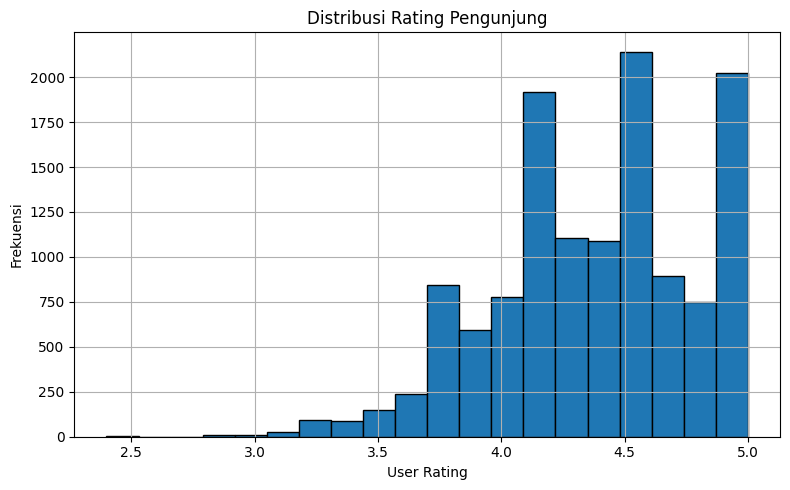

count    12744.000000
mean         4.378013
std          0.418924
min          2.400000
25%          4.100000
50%          4.400000
75%          4.700000
max          5.000000
Name: user_rating, dtype: float64

In [17]:
plt.figure(figsize=(8, 5))
df["user_rating"].dropna().hist(bins=20, edgecolor="black")
plt.title("Distribusi Rating Pengunjung")
plt.xlabel("User Rating")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

display(df["user_rating"].describe())

**Interpretasi:** perhatikan apakah rating terkonsentrasi pada nilai tertentu, apakah distribusinya miring, serta rentang minimum dan maksimum. Distribusi yang sangat terkonsentrasi dapat membuat prediksi mendekati rata-rata terlihat baik; karena itu model perlu dibandingkan dengan baseline sederhana.

### 3.3 Distribusi Fitur Numerik

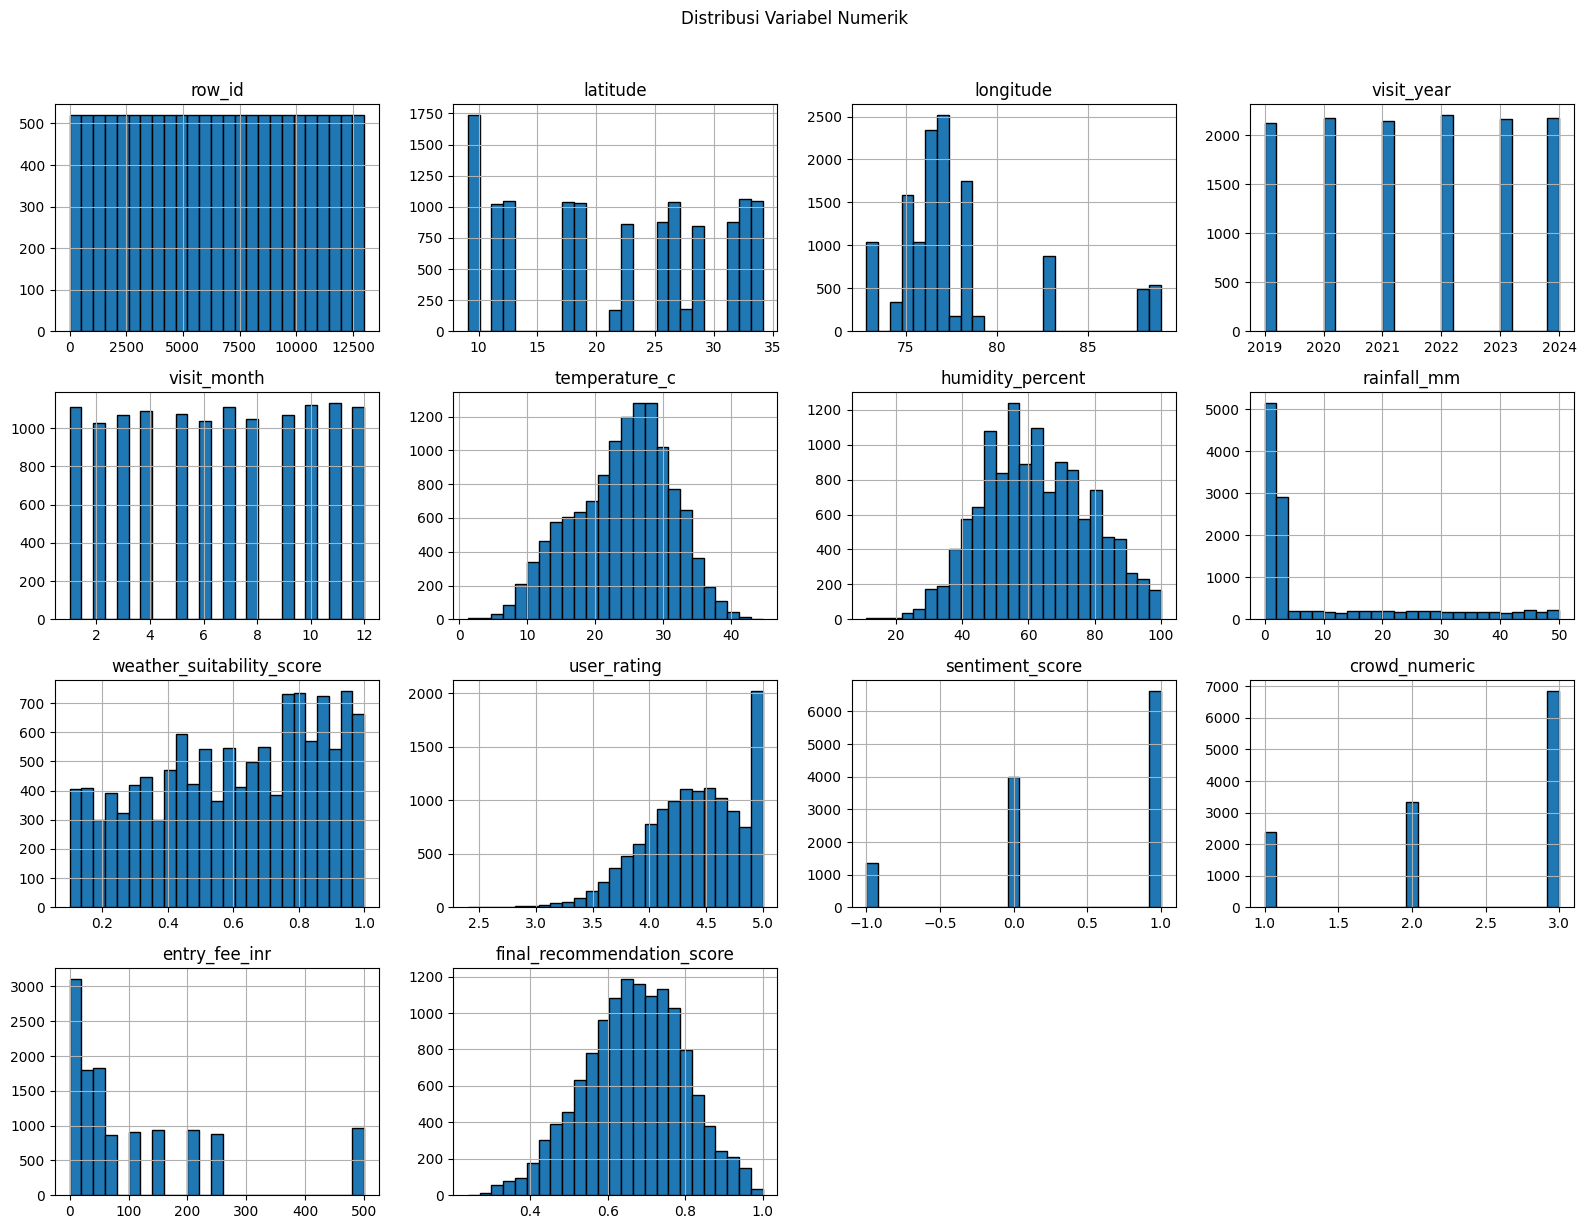

In [18]:
numeric_all = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_all].hist(figsize=(16, 12), bins=25, edgecolor="black")
plt.suptitle("Distribusi Variabel Numerik", y=1.02)
plt.tight_layout()
plt.show()

**Interpretasi:** gunakan histogram untuk mengenali kemencengan distribusi, rentang yang tidak wajar, dan kemungkinan outlier. Jangan menghapus outlier hanya karena nilainya ekstrem; pastikan ada alasan substantif.

### 3.4 Korelasi Awal dengan Target

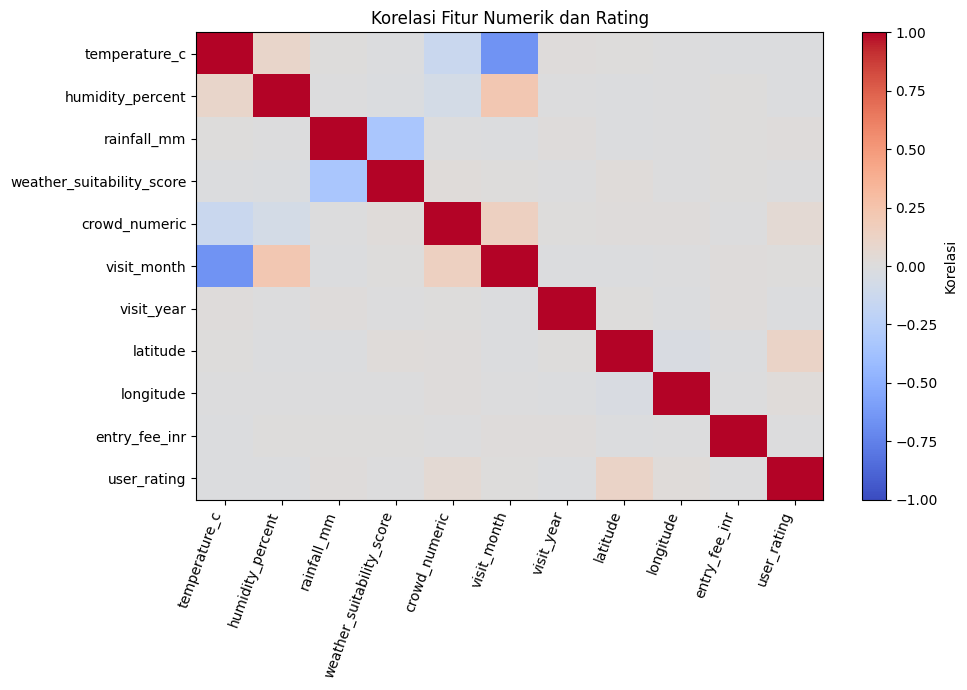

,korelasi_dengan_rating
user_rating,1.000000
latitude,0.116363
crowd_numeric,0.051995
longitude,0.022117
rainfall_mm,0.010609
visit_month,0.003061
entry_fee_inr,-0.001632
weather_suitability_score,-0.004509
visit_year,-0.010563
temperature_c,-0.012912


In [19]:
candidate_numeric = [
    "temperature_c", "humidity_percent", "rainfall_mm",
    "weather_suitability_score", "crowd_numeric",
    "visit_month", "visit_year", "latitude", "longitude",
    "entry_fee_inr"
]
available_candidates = [c for c in candidate_numeric if c in df.columns]
corr_data = df[available_candidates + ["user_rating"]].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
plt.imshow(corr_data, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Korelasi")
plt.xticks(range(len(corr_data.columns)), corr_data.columns, rotation=70, ha="right")
plt.yticks(range(len(corr_data.index)), corr_data.index)
plt.title("Korelasi Fitur Numerik dan Rating")
plt.tight_layout()
plt.show()

display(corr_data["user_rating"].sort_values(ascending=False).to_frame("korelasi_dengan_rating"))

**Interpretasi:** korelasi menunjukkan hubungan linear awal, bukan sebab-akibat. Korelasi yang rendah tidak otomatis berarti fitur tidak berguna bagi Random Forest, karena model pohon dapat menangkap pola non-linear. Periksa juga apakah fitur berpotensi dibentuk dari target.

## 4. Cleaning dan Preprocessing

### 4.1 Menentukan Target dan Fitur

Target adalah `user_rating`. Fitur awal dipilih dari variabel numerik yang masuk akal secara konteks. Kolom ID (`row_id`, `place_id`) tidak digunakan sebagai prediktor. Kolom yang berpotensi menjadi kebocoran target, seperti `sentiment_score` dan `final_recommendation_score`, dikeluarkan karena definisi/formula pembentukannya tidak dipastikan dan dapat berkaitan langsung dengan penilaian/rekomendasi.

Kolom `sentiment_label`, `review_text`, `would_revisit`, dan `would_recommend` tidak digunakan karena bukan fitur numerik yang dibahas dalam rancangan ini.

In [20]:
target = "user_rating"
feature_candidates = [
    "temperature_c", "humidity_percent", "rainfall_mm",
    "weather_suitability_score", "crowd_numeric",
    "visit_month", "visit_year", "latitude", "longitude",
    "entry_fee_inr"
]
features = [c for c in feature_candidates if c in df.columns]

print("Target:", target)
print("Fitur numerik terpilih:", features)
print("Jumlah fitur:", len(features))

Target: user_rating
Fitur numerik terpilih: ['temperature_c', 'humidity_percent', 'rainfall_mm', 'weather_suitability_score', 'crowd_numeric', 'visit_month', 'visit_year', 'latitude', 'longitude', 'entry_fee_inr']
Jumlah fitur: 10


### 4.2 Menangani Target Kosong dan Duplikasi

Baris yang targetnya kosong dikeluarkan karena nilai rating yang hendak diprediksi tidak tersedia. Duplikasi identik diperiksa dan dihapus jika ditemukan. Missing value pada fitur tidak diisi sebelum pemisahan data; imputasi dilakukan di dalam pipeline setelah data dibagi.

In [21]:
data_model = df[["place_id", target] + features].copy()
before_rows = len(data_model)

data_model = data_model.dropna(subset=[target])
data_model = data_model.drop_duplicates()

print("Jumlah baris awal:", before_rows)
print("Jumlah baris setelah target kosong dan duplikasi ditangani:", len(data_model))
print("Missing target setelah cleaning:", data_model[target].isna().sum())
display(data_model[features + [target]].isna().sum().to_frame("missing_setelah_filter"))

Jumlah baris awal: 13000
Jumlah baris setelah target kosong dan duplikasi ditangani: 12744
Missing target setelah cleaning: 0


,missing_setelah_filter
temperature_c,505
humidity_percent,345
rainfall_mm,663
weather_suitability_score,505
crowd_numeric,418
visit_month,0
visit_year,0
latitude,155
longitude,117
entry_fee_inr,747


### 4.3 Pemeriksaan Rentang Target dan Fitur

Periksa nilai minimum dan maksimum untuk memastikan rentang masuk akal berdasarkan dokumentasi dataset. Jika ditemukan nilai yang tidak valid, dokumentasikan alasan dan aturan penanganannya. Jangan menetapkan batas rating tanpa merujuk definisi skala rating pada sumber data.

In [22]:
display(data_model[features + [target]].describe().T)

,count,mean,std,min,25%,50%,75%,max
temperature_c,12239.0,23.980064,7.083997,1.300000,19.000000,24.800000,29.100000,44.600000
humidity_percent,12399.0,62.387209,16.066907,11.000000,50.000000,61.000000,74.000000,100.000000
rainfall_mm,12081.0,10.304222,14.421514,0.000000,1.200000,2.300000,16.700000,50.000000
weather_suitability_score,12239.0,0.603442,0.259121,0.100000,0.400000,0.630000,0.830000,1.000000
crowd_numeric,12326.0,2.353237,0.781116,1.000000,2.000000,3.000000,3.000000,3.000000
visit_month,12744.0,6.552338,3.468121,1.000000,4.000000,7.000000,10.000000,12.000000
visit_year,12744.0,2021.509259,1.704279,2019.000000,2020.000000,2022.000000,2023.000000,2024.000000
latitude,12589.0,21.752460,8.516236,9.095049,12.302003,22.553801,28.614775,34.132772
longitude,12627.0,77.708481,3.876749,72.818835,75.820458,76.706565,78.121216,89.001084
entry_fee_inr,11997.0,107.302242,137.545201,0.000000,0.000000,50.000000,150.000000,500.000000


### 4.4 Pemisahan Data Berdasarkan Destinasi

Dataset memiliki banyak catatan untuk destinasi yang sama. Pemisahan acak per baris berisiko menempatkan catatan dari destinasi yang sama ke data latih dan data uji. Untuk menguji kemampuan generalisasi ke destinasi yang tidak terlihat saat pelatihan, digunakan `GroupShuffleSplit` dengan `place_id` sebagai kelompok.

Jika tujuan penelitian sebenarnya hanya memprediksi kunjungan baru pada destinasi yang sudah pernah diamati, strategi split dapat berbeda dan harus dijelaskan.

In [23]:
X = data_model[features]
y = data_model[target]
groups = data_model["place_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_places = set(groups.iloc[train_idx])
test_places = set(groups.iloc[test_idx])

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)
print("Destinasi latih:", len(train_places))
print("Destinasi uji:", len(test_places))
print("Irisan destinasi latih-uji:", len(train_places.intersection(test_places)))

Data latih: (10186, 10)
Data uji: (2558, 10)
Destinasi latih: 59
Destinasi uji: 15
Irisan destinasi latih-uji: 0


### 4.5 Imputasi dan Standardisasi

Nilai kosong pada fitur numerik diisi menggunakan median dari data latih. Standardisasi digunakan pada Linear Regression sebagai bagian dari pipeline agar skala fitur lebih sebanding. Random Forest tidak memerlukan standardisasi, tetapi tetap menggunakan imputasi median. Pipeline memastikan proses preprocessing dipelajari dari data latih saja.

## 5. Modelling

Dua model dari materi praktikum dibandingkan:

1. **Linear Regression:** model dasar yang mempelajari hubungan linear antara fitur dan target. Model ini relatif mudah diinterpretasikan.
2. **Random Forest Regression:** gabungan beberapa decision tree yang dapat menangkap hubungan non-linear dan interaksi fitur.

Kedua model menggunakan data latih dan diuji pada data uji yang sama agar perbandingan adil.

## 6. Evaluation

### 6.1 Metrik Evaluasi

- **MAE (Mean Absolute Error):** rata-rata besar kesalahan absolut prediksi. Jika MAE = 0,30, secara rata-rata prediksi meleset sekitar 0,30 poin rating.
- **RMSE (Root Mean Squared Error):** akar rata-rata kuadrat kesalahan; lebih sensitif terhadap kesalahan besar.
- **R²:** proporsi variasi target yang dapat dijelaskan model pada data uji. Nilai dapat negatif jika model lebih buruk daripada prediksi rata-rata sederhana.

Model yang baik diharapkan memiliki MAE dan RMSE rendah serta R² lebih tinggi. Interpretasi tetap mempertimbangkan distribusi target dan baseline.

### 6.2 Visualisasi Aktual vs Prediksi

### 6.4 Distribusi Residual

### 6.5 Penentuan Model Terbaik

Model terbaik ditentukan dari hasil aktual pada tabel metrik, bukan ditentukan sebelumnya. Prioritaskan MAE yang lebih rendah karena mudah diterjemahkan ke satuan poin rating; gunakan RMSE dan R² sebagai pertimbangan tambahan. Jika hasil metrik saling bertentangan, jelaskan trade-off tersebut.